#### ESCULA POLITECNICA NACIONAL 
#### METODOS NUMERICOS 
#### TALLER N4- Interpolacion Y Polinomios de Taylor

### CAIZA DANNY 
Fecha: 23 de Octubre de 2026 

___________________

* Parte B. Python básico

Responda primero sin ejecutar el código y después compruébelo en Python. Si su respuesta y la de Python no coinciden, discútalo con su grupo antes de seguir.


In [1]:
x = 0.5
suma = 0
termino = 1
for k in range(1, 4):
    suma = suma + termino
    termino = termino * x / k
print(suma)

1.625


In [2]:
import math
import numpy as np

def horner(coefs, x):
    p = 0
    for a in coefs:
        p = p * x + a
    return p

In [3]:
print(horner([2, -3, 0, 1, -5], 2))

5


In [4]:
print(horner([-5, 1, 0, -3, 2], 2))

-76


In [5]:
math.exp(np.linspace(0, 1, 5))

TypeError: only length-1 arrays can be converted to Python scalars

In [6]:
horner([2, -3, 0, 1, -5], np.linspace(0, 1, 5))

array([-5.       , -4.7890625, -4.75     , -4.8828125, -5.       ])

* Parte C. Verificación con gráficas

Programe en su computador, compare con su grupo y registre aquí los resultados. Guarde todo en un solo repositorio: la última pregunta pide el enlace.

P_3(1.5)  = 0.416667
P_10(1.5) = 0.405435
P_10(2.5) = -2.403097


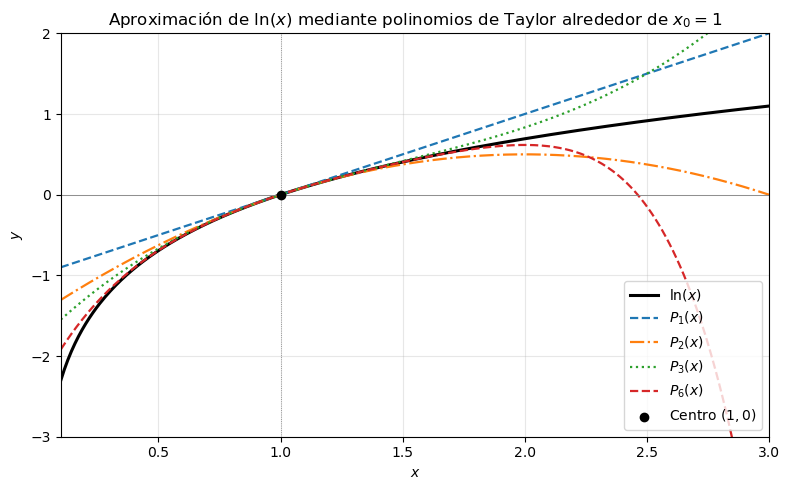

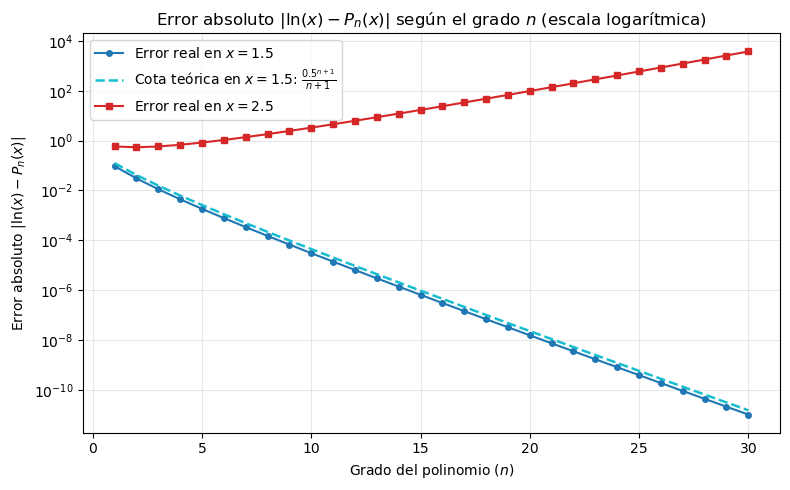

In [7]:
import numpy as np
import matplotlib.pyplot as plt


def taylor_ln(x, n):
    """Polinomio de Taylor de grado n de ln(x) alrededor de x0 = 1."""
    suma = 0
    for k in range(1, n + 1):
        suma = suma + ((-1) ** (k + 1)) * ((x - 1) ** k) / k
    return suma

print(f"P_3(1.5)  = {taylor_ln(1.5, 3):.6f}")
print(f"P_10(1.5) = {taylor_ln(1.5, 10):.6f}")
print(f"P_10(2.5) = {taylor_ln(2.5, 10):.6f}")

x = np.linspace(0.1, 3, 400)

plt.figure(figsize=(8, 5))
plt.plot(x, np.log(x), label=r"$\ln(x)$", color="black", linewidth=2.2)

estilos = [
    (1, "--", "tab:blue"),
    (2, "-.", "tab:orange"),
    (3, ":", "tab:green"),
    (6, "--", "tab:red"),
]

for grado, estilo, color in estilos:
    plt.plot(
        x,
        taylor_ln(x, grado),
        linestyle=estilo,
        color=color,
        linewidth=1.6,
        label=rf"$P_{grado}(x)$",
    )

plt.scatter([1], [0], color="black", zorder=5, label="Centro $(1, 0)$")
plt.ylim(-3, 2)
plt.xlim(0.1, 3)
plt.axhline(0, color="gray", linewidth=0.6)
plt.axvline(1, color="gray", linewidth=0.6, linestyle=":")
plt.title(r"Aproximación de $\ln(x)$ mediante polinomios de Taylor alrededor de $x_0 = 1$")
plt.xlabel(r"$x$")
plt.ylabel(r"$y$")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("grafica_1_taylor_ln.png", dpi=200)
plt.show()

grados = np.arange(1, 31)
err_15 = [abs(np.log(1.5) - taylor_ln(1.5, int(n))) for n in grados]
err_25 = [abs(np.log(2.5) - taylor_ln(2.5, int(n))) for n in grados]
cota_15 = (0.5 ** (grados + 1)) / (grados + 1)

plt.figure(figsize=(8, 5))
plt.semilogy(grados, err_15, "o-", label=r"Error real en $x = 1.5$", color="tab:blue", markersize=4)
plt.semilogy(
    grados,
    cota_15,
    "--",
    label=r"Cota teórica en $x = 1.5$: $\frac{0.5^{n+1}}{n+1}$",
    color="tab:cyan",
    linewidth=1.8,
)
plt.semilogy(grados, err_25, "s-", label=r"Error real en $x = 2.5$", color="tab:red", markersize=4)

plt.title(r"Error absoluto $|\ln(x) - P_n(x)|$ según el grado $n$ (escala logarítmica)")
plt.xlabel(r"Grado del polinomio ($n$)")
plt.ylabel(r"Error absoluto $|\ln(x) - P_n(x)|$")
plt.legend(loc="best")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("grafica_2_error_ln.png", dpi=200)
plt.show()